In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import evaluate_model,plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import tensorflow as tf

In [24]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    # callbacks = [
    # tf.keras.callbacks.EarlyStopping(
    #     monitor='val_loss',
    #     patience=patience,
    #     restore_best_weights=True
    # )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    shuffle=False
    # callbacks=callbacks
    )
    print(patience)
    return history

<h1> Import Data and remove NANs

Text(0.5, 0.98, 'All Data')

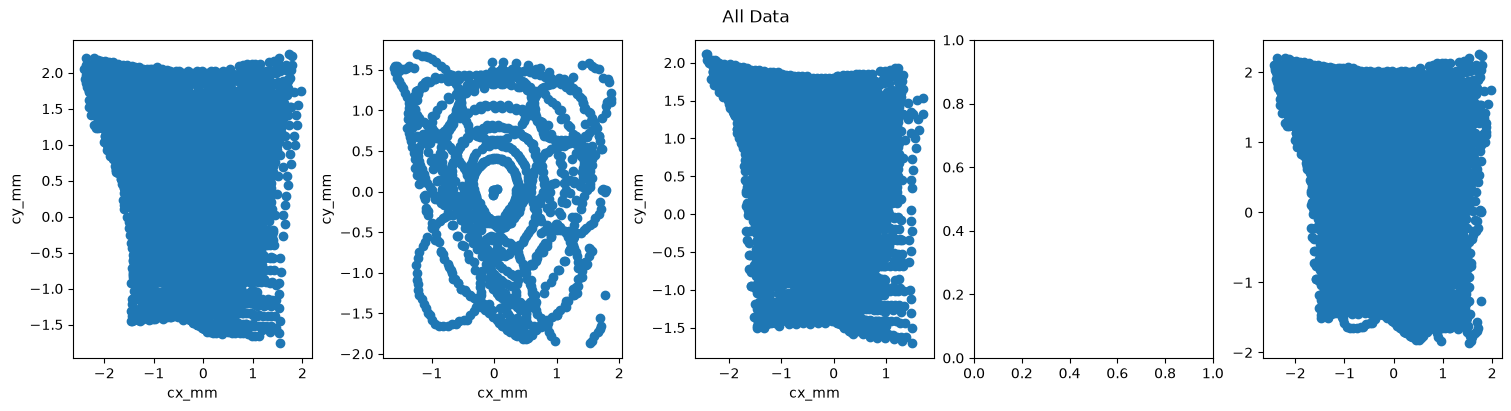

In [25]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [ data_1, data_2, data_3] #data_0, #get better results without data_0

all_data = pd.concat(data_list, ignore_index=True)

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
axs[4].scatter(all_data["cx_mm"], all_data["cy_mm"])
fig.suptitle("All Data")

<h2> Create StandardScalers based on all data

In [26]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets</h2>
This was for when I was going to train the model on each dataset sequentially. 

Now I am just training it on all of them concatenated, so it is not needed

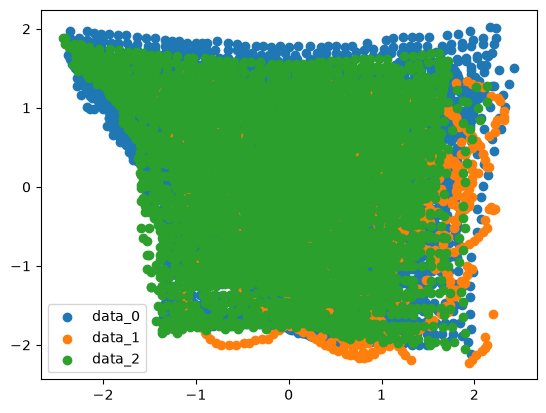

In [27]:
scaled = {}
for i, data in enumerate(data_list):
    scaled[f"X_scaled_{i}"] = scalerX.transform(data[["cx_mm", "cy_mm"]])
    scaled[f"y_scaled_{i}"] = scalerY.transform(data[["s0", "s1", "s2"]])
    plt.scatter(scaled[f"X_scaled_{i}"][:,0], scaled[f"X_scaled_{i}"][:,1], label=f"data_{i}")
    plt.legend()
#plotting just to check that they have all scaled correctly. 

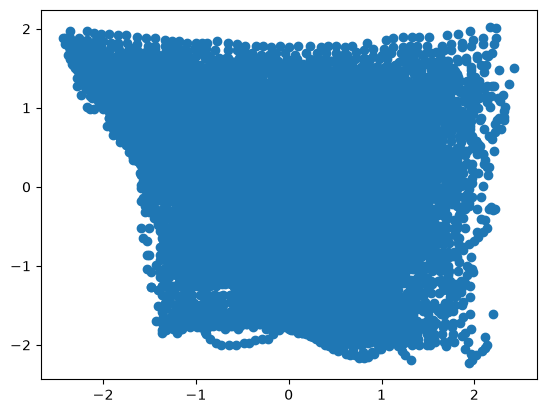

In [28]:
X_scaled_all = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled_all = scalerY.transform(all_data[["s0", "s1", "s2"]])
plt.scatter(X_scaled_all[:,0], X_scaled_all[:,1])
#plotting just to check that they have all scaled correctly. 

<h1>Linear Regression

In [71]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3, constrained_layout=True)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

Fold, 0:
  Train: index=0 to 2274 
  Test:  index=2275 to 4548

Linear Regression Results:
  Overall R2:  0.9117
  Weighted R2: 0.9099
Fold, 1:
  Train: index=0 to 4548 
  Test:  index=4549 to 6822

Linear Regression Results:
  Overall R2:  0.9229
  Weighted R2: 0.9208
Fold, 2:
  Train: index=0 to 6822 
  Test:  index=6823 to 9096

Linear Regression Results:
  Overall R2:  0.9084
  Weighted R2: 0.9042
MSE scores for each fold: [0.07596921175718307, 0.07780680060386658, 0.07629632949829102]


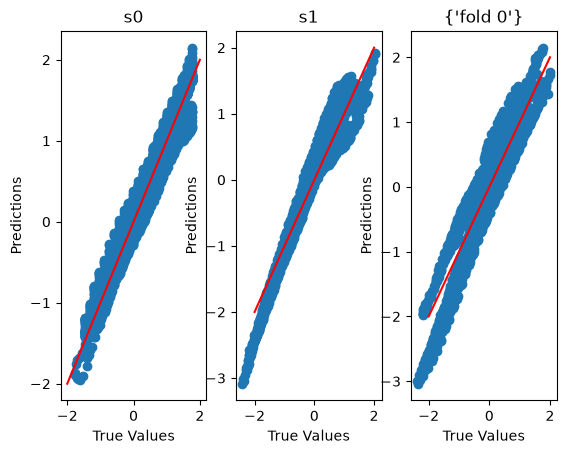

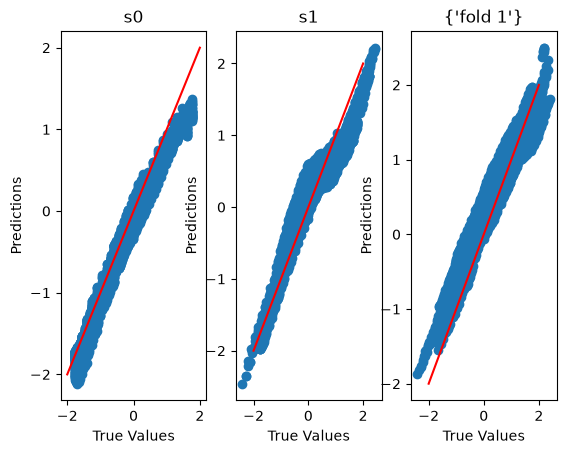

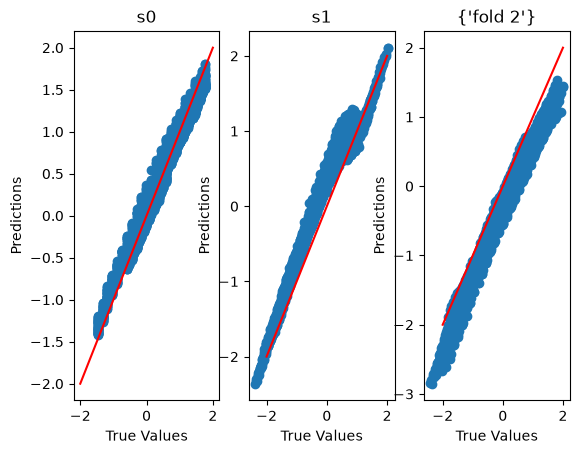

In [30]:
#LR sklearn - all data concat trained. 
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    lin_reg = LinearRegression()
    lin_reg.fit(X_train, y_train)
    y_pred = lin_reg.predict(X_test)
    evaluate_model("Linear Regression", y_test, y_pred)

    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plt.title({f"fold {i}"})

print("MSE scores for each fold:", scores)

In [31]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
# plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
# plt.colorbar()
# plt.title("x and y values input into snake scan. (color=index)")
snake_predictions = lin_reg.predict(mesh0045_27Oct[["x", "y"]])
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)
print(snake_pred_inverse)
np.savetxt("predictions/all_data_LR_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')

[[ 4516.15149767 -5841.08534267  1324.93579513]
 [ 4487.44794485 -5530.40448548  1042.95853623]
 [ 4458.74439203 -5219.72362829   760.98127733]
 ...
 [-4380.21590273  5629.60942475 -1249.39051184]
 [-4408.91945555  5940.29028194 -1531.36777074]
 [-4437.62300837  6250.97113913 -1813.34502965]]


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


Surprisingly high R2 for Linear Regression - maybe a mistake ?

Try with tensorflow too

<h2> LR with tensorflow</h2>
A single layer MLP with a linear activation function should give a linear regression model.

Fold, 0:
  Train: index=0 to 2274 
  Test:  index=2275 to 4548
1

Fold: 0 Results (scaled):
  Overall R2:  0.0448
  Weighted R2: 0.0470
Fold, 1:
  Train: index=0 to 4548 
  Test:  index=4549 to 6822
1

Fold: 1 Results (scaled):
  Overall R2:  0.4494
  Weighted R2: 0.4207
Fold, 2:
  Train: index=0 to 6822 
  Test:  index=6823 to 9096
1

Fold: 2 Results (scaled):
  Overall R2:  0.3711
  Weighted R2: 0.4045
MSE scores for each fold: [0.8037312030792236, 0.5691528916358948, 0.47437214851379395]


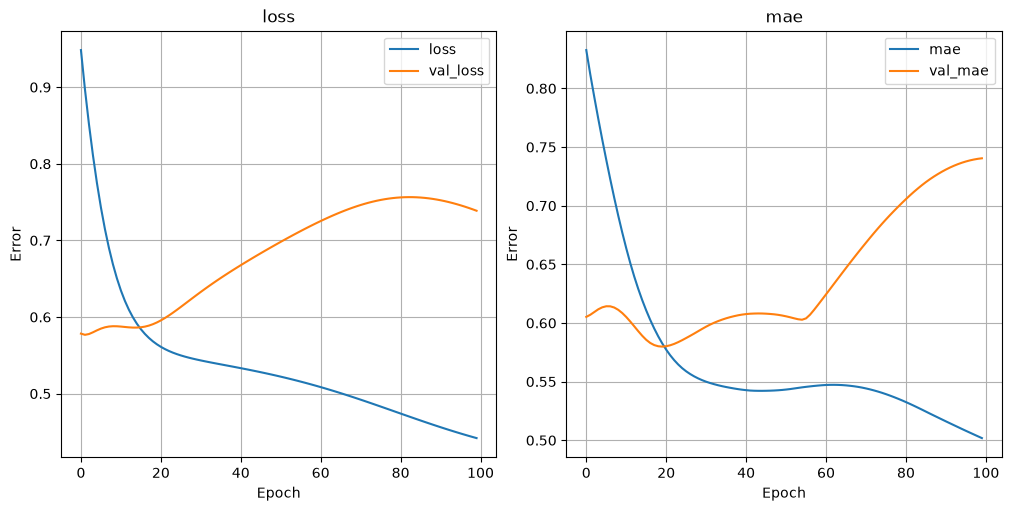

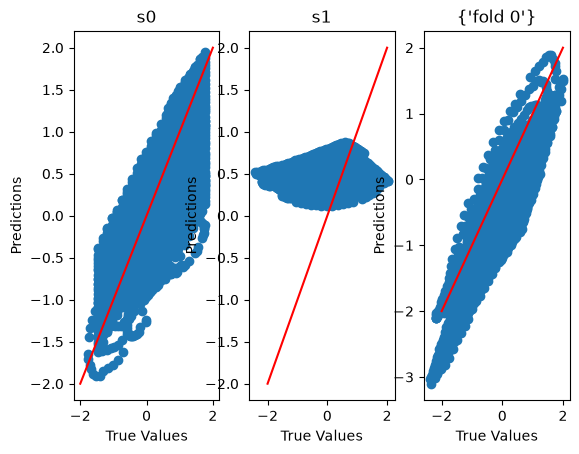

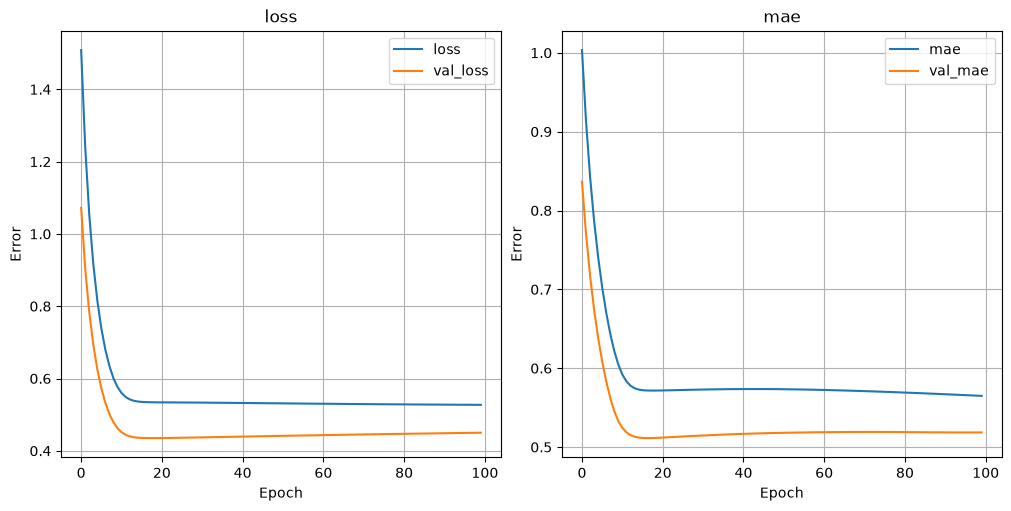

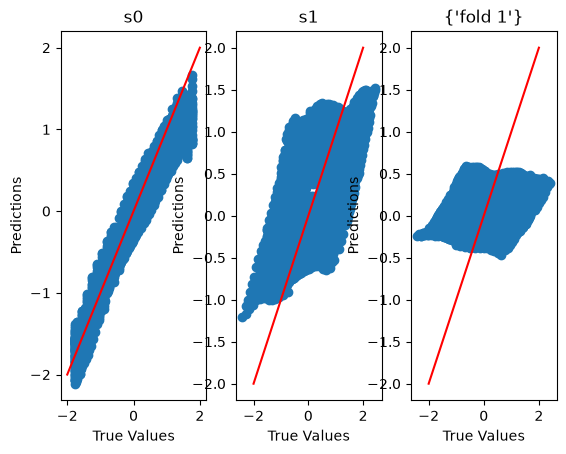

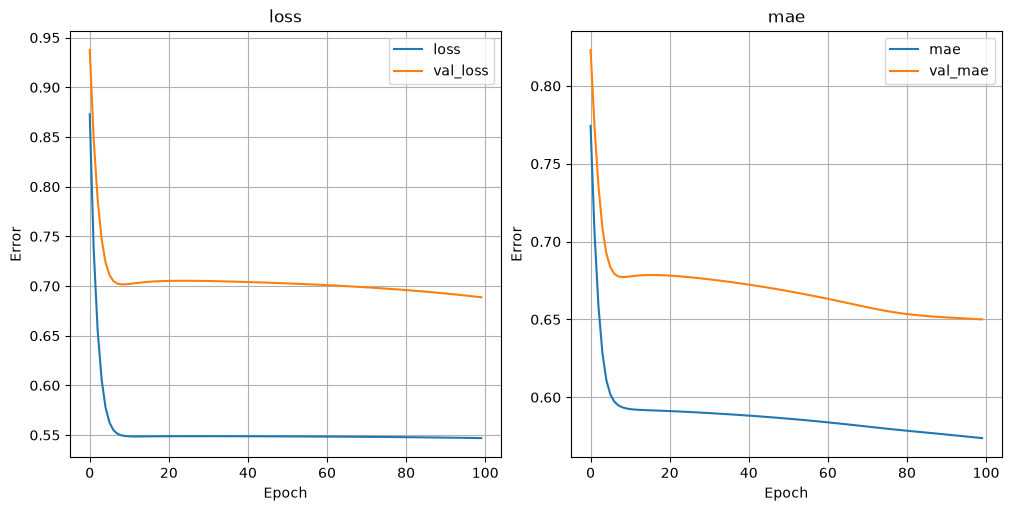

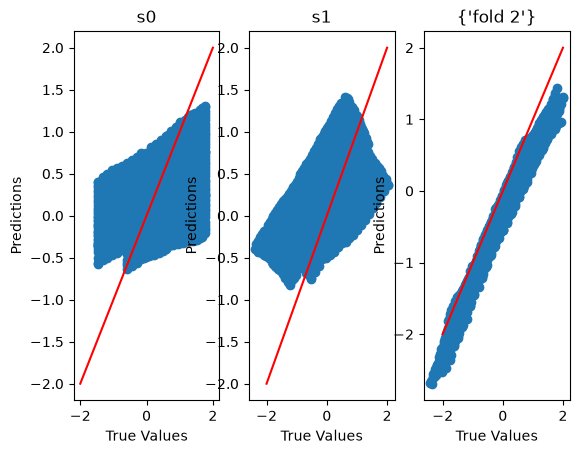

In [32]:
#LR tensorflow - all data concat trained. 
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model =  tf.keras.models.Sequential(
    [
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(
            units=1, activation="linear"
        ),  # Linear activation = Linear Regression
        tf.keras.layers.Dense(y_train.shape[1],)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae'])
    

    history = train_model(model, X_train, y_train, verbose=0, epochs=100, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

    plot_loss_and_mae(history)

    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plt.title({f"fold {i}"})

print("MSE scores for each fold:", scores)

<h1>MLP

setup

In [47]:
def plot_converted_loss(loss, val_loss):
  fig, axs = plt.subplots(1, 2, figsize=(10,5), constrained_layout=True)
  for i, value in enumerate(['loss']):
    subplot = axs[i]
    subplot.plot(loss, label=value)
    subplot.plot(val_loss, label=f'val_{value}')
  #   plt.ylim([0, 10])
    subplot.set_xlabel('Epoch')
    subplot.set_ylabel('Error')
    subplot.legend()
    subplot.grid(True)
    subplot.set_title(value)

In [64]:
all_data["motor_squared"] = all_data["s1"] * all_data["s1"]
display(all_data["motor_squared"].head(5))
scalerError = StandardScaler().fit(all_data[["motor_squared"]])

0           0.0
1           0.0
2    70442448.0
3    63186600.0
4    56340036.0
Name: motor_squared, dtype: float32

<h2>MLP training on each dataset separately - old 

In [ ]:
# training pm data adding each data set separately 
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for data in range(3):
    X = scaled[f"X_scaled_{data}"]
    y = scaled[f"y_scaled_{data}"]
    for i, (train_index, test_index) in enumerate(tscv.split(X)):
        print(f"Fold{data}, {i}:")
        print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
        print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
        
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        model = build_nn_model(X_train.shape[1], y_train.shape[1])

        history = train_model(model, X_train, y_train, verbose=0, epochs=50, patience=1)
        y_pred = model.predict(X_test, verbose=0)

        evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
        # plot_motors(y_test, y_pred, [-2,2])

        error = mean_squared_error(y_test, y_pred)
        scores.append(error)
        # plot_loss_and_mae(history)
        loss = history.history['loss']
        val_loss = history.history['val_loss']
        converted_loss = scalerError.inverse_transform(np.sqrt(loss).reshape(-1, 1))
        converted_val_loss = scalerError.inverse_transform(np.sqrt(val_loss).reshape(-1, 1))
        plot_converted_loss(converted_loss, converted_val_loss)
        # break

print("MSE scores for each fold:", scores)

<h2>MLP training with all data concatenated

Fold, 0:
  Train: index=0 to 2274 
  Test:  index=2275 to 4548
1

Fold: 0 Results (scaled):
  Overall R2:  0.8698
  Weighted R2: 0.8678
Fold, 1:
  Train: index=0 to 4548 
  Test:  index=4549 to 6822
1

Fold: 1 Results (scaled):
  Overall R2:  0.9005
  Weighted R2: 0.8983
Fold, 2:
  Train: index=0 to 6822 
  Test:  index=6823 to 9096
1

Fold: 2 Results (scaled):
  Overall R2:  0.8719
  Weighted R2: 0.8646
MSE scores for each fold: [0.11146970838308334, 0.09988772124052048, 0.10784534364938736]


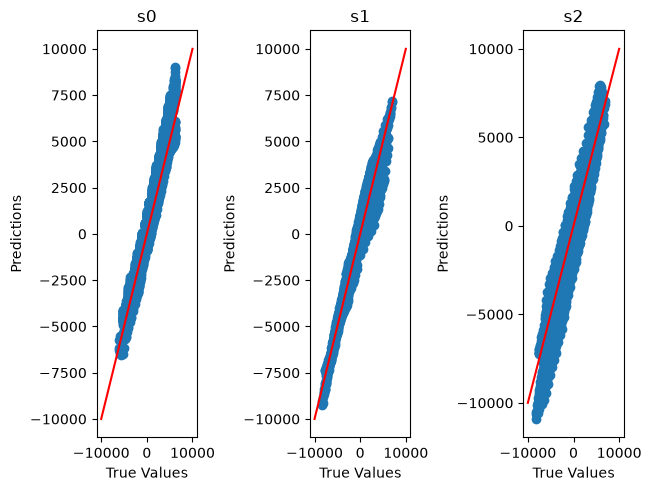

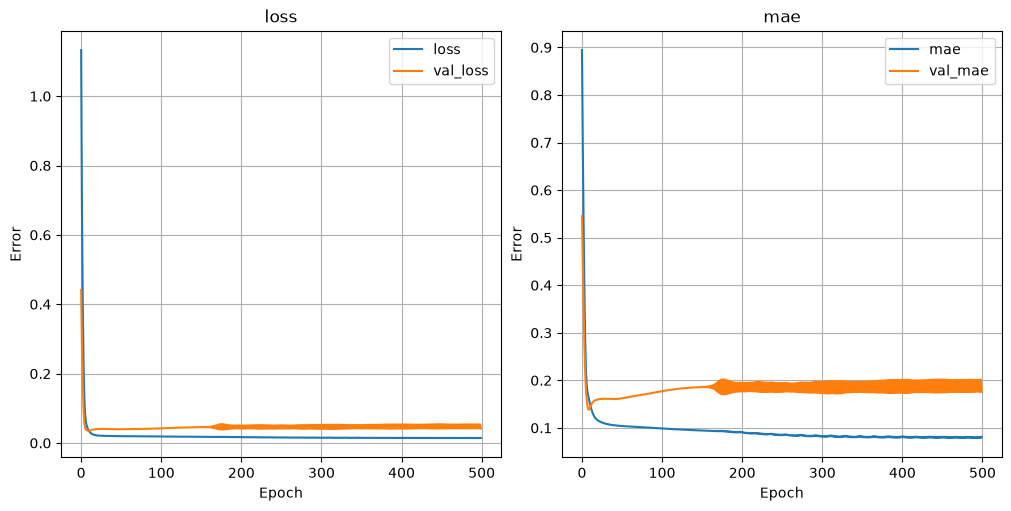

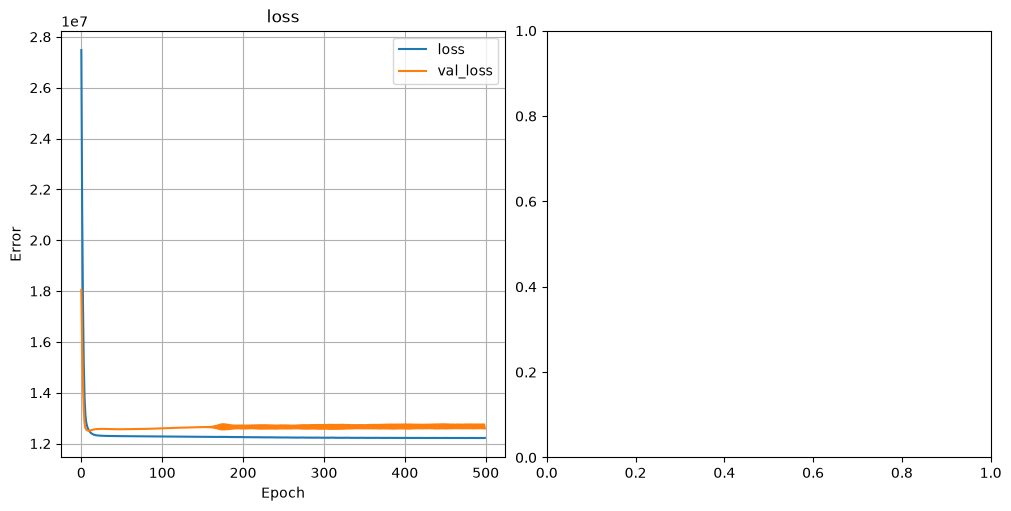

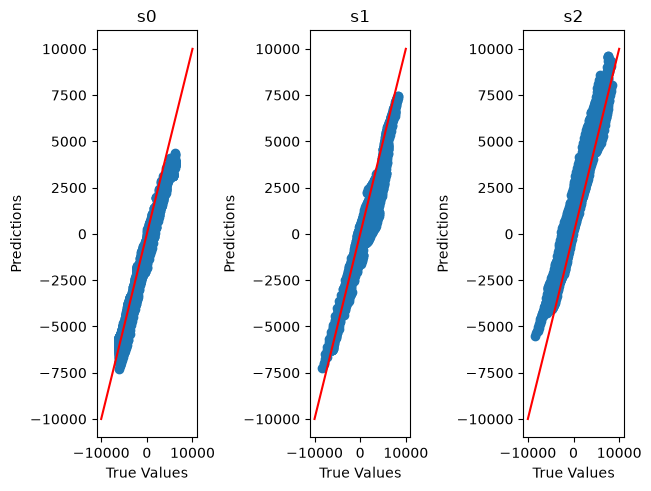

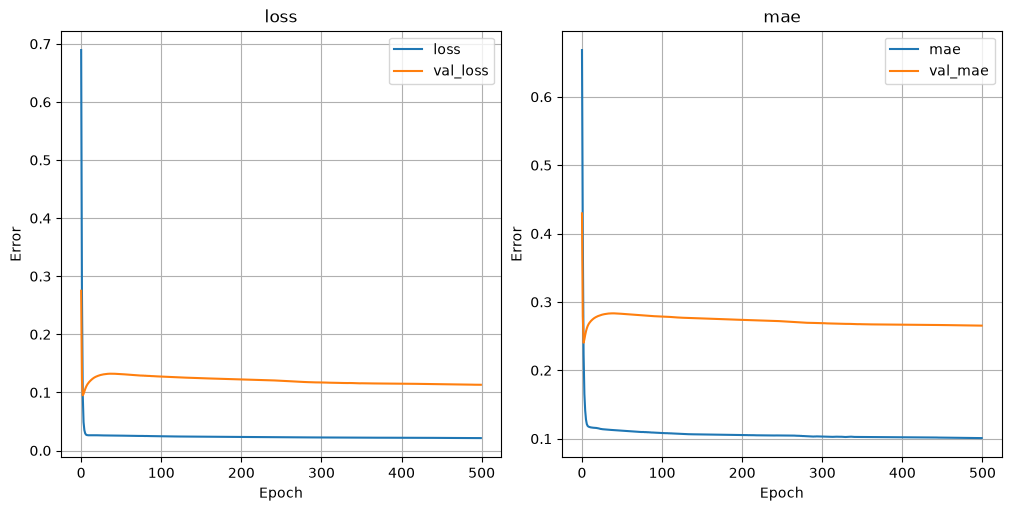

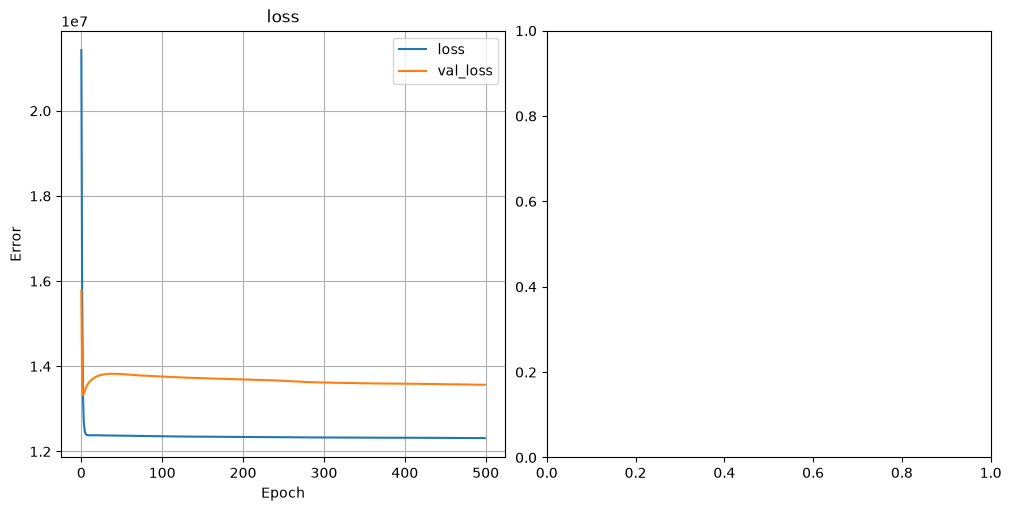

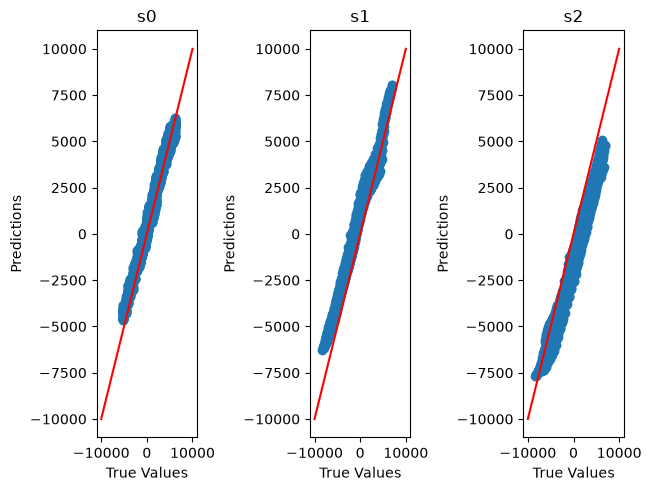

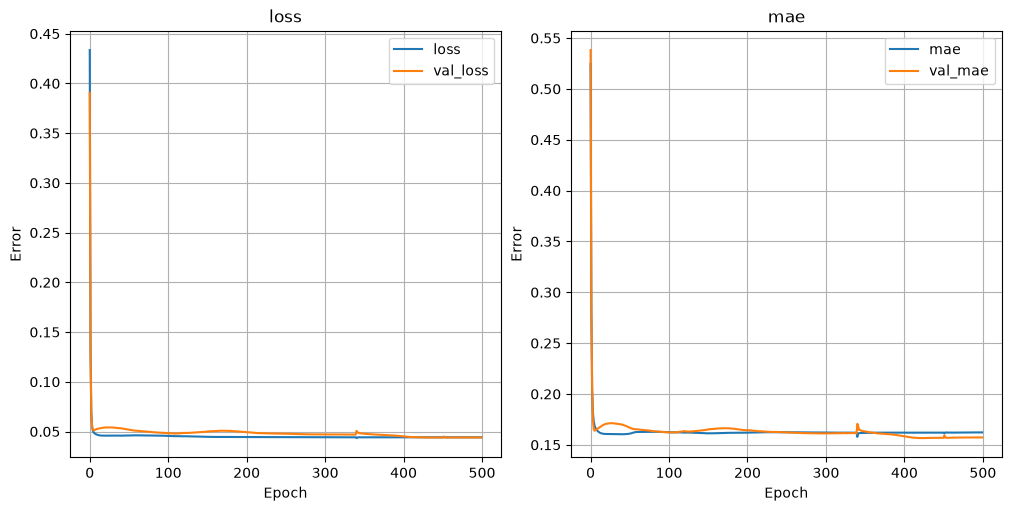

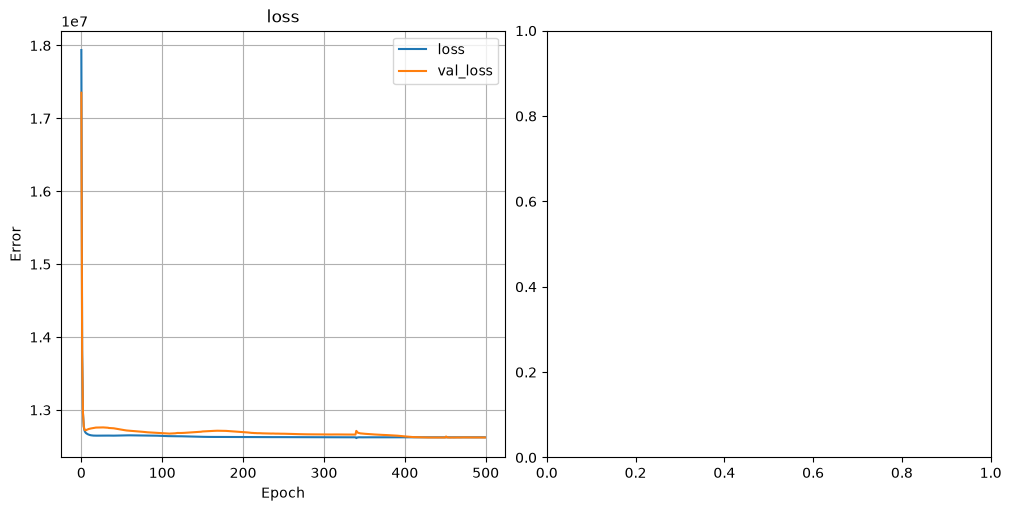

In [73]:
#Training with all data concatenated
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_train.shape[1], y_train.shape[1])

    history = train_model(model, X_train, y_train, verbose=0, epochs=500, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

    y_test_inverse = scalerY.inverse_transform(y_test)
    y_pred_inverse = scalerY.inverse_transform(y_pred)
    plot_motors(y_test_inverse, y_pred_inverse, [-10000,10000])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)
    # plt.title({f"Data, fold {i}"})
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    converted_loss = scalerError.inverse_transform(np.array(loss).reshape(-1,1))
    converted_val_loss = scalerError.inverse_transform(np.array(val_loss).reshape(-1,1))
    plot_converted_loss(converted_loss, converted_val_loss)

print("MSE scores for each fold:", scores)

<h1> Using final model to predict basic snake scan 

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 789us/step
[[ 4905.7983  -5035.4624    333.83475]
 [ 4907.668   -4813.21       91.4711 ]
 [ 4909.5376  -4590.9575   -150.89253]
 ...
 [-4602.2104   6816.6606  -2186.1443 ]
 [-4637.16     7053.359   -2375.3928 ]
 [-4671.955    7290.699   -2566.0623 ]]


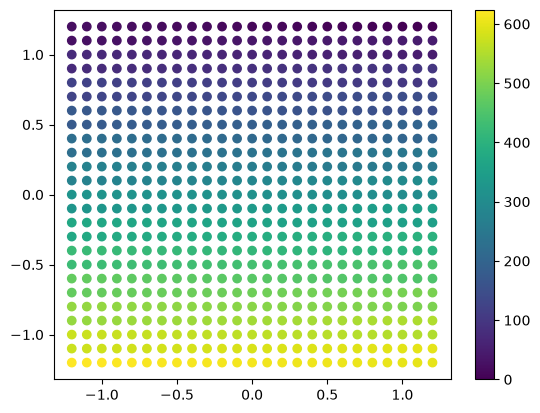

In [ ]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv") #get basic snake scan x and y values
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()
snake_predictions = model.predict(mesh0045_27Oct[["x", "y"]])
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)
print(snake_pred_inverse)
np.savetxt("predictions/all_data_MLP_pred_snake.csv", snake_pred_inverse, delimiter=',')